# E7: what happens when many rows share a key?

Same 114,000 rows, three key columns with very different amounts of duplication:

| column | distinct keys | rows per key |
|---|---|---|
| `track_id` | 89,741 | about 1.3 |
| `track_genre` | 114 | exactly 1,000 |
| `popularity` | 101 | about 1,129 |

Measured: build, point lookups (hits), and range queries on `popularity` at three selectivities.
Data: `E7_duplicate_keys` rows, one machine, one code version.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv(Path("..") / "results" / "timings.csv")
e7 = df[(df["experiment"] == "E7_duplicate_keys") & (df["machine_id"] == "zaid-mbp")]
version = e7["code_version"].iloc[-1]
e7 = e7[e7["code_version"] == version].copy()

e7["us_per_op"] = e7["total_ns"] / e7["n_ops"] / 1_000
for c in ["comparisons", "nodes_visited", "rotations", "splits"]:
    e7[c + "_per_op"] = e7[c] / e7["n_ops"]

COLUMNS = ["track_id", "track_genre", "popularity"]          # least to most duplicated
INDEXES = ["unsorted_list", "sorted_list", "hash_table", "avl_tree", "bplus_tree", "ref_dict", "ref_bisect"]

print("code version", version, "|", len(e7), "rows")
e7.groupby(["key_column", "operation"]).size().unstack()

code version b8f1dc3 | 315 rows


operation,build,point_hit,range
key_column,,,
popularity,35.0,35.0,105.0
track_genre,35.0,35.0,NaN
track_id,35.0,35.0,NaN


## Median and IQR over the 5 replicates (µs per operation)

In [2]:
def q(p):
    return lambda g: g.quantile(p)

stats = (e7.groupby(["key_column", "operation", "operation_param", "index_type"], dropna=False)["us_per_op"]
         .agg(q25=q(0.25), median="median", q75=q(0.75)).reset_index())
stats["operation_param"] = stats["operation_param"].fillna("")

table = stats.pivot_table(index=["key_column", "operation", "operation_param"], columns="index_type",
                          values="median")[INDEXES]
table.round(2)

index_type                             unsorted_list  sorted_list  hash_table  \
key_column  operation operation_param                                           
popularity  build                               0.09         0.57        0.34   
            point_hit 1.0                    1438.57         0.59        0.24   
            range     0.01                   2078.62         4.22       14.17   
                      0.1                    2232.44        31.20       39.45   
                      0.25                   2425.33        80.03       86.54   
track_genre build                               0.20         0.57        0.42   
            point_hit 1.0                    8398.30         0.82        0.38   
track_id    build                               0.13        11.09        1.10   
            point_hit 1.0                    5035.04         3.02        1.48   

index_type                             avl_tree  bplus_tree  ref_dict  \
key_column  operation operation_param                                   
popularity  build                          1.95        0.88      0.11   
            point_hit 1.0                  0.38        0.81      0.06   
            range     0.01                 3.96        4.42      6.79   
                      0.1                 31.38       31.57     32.19   
                      0.25                83.24       81.07     79.91   
track_genre build                          2.12        0.78      0.15   
            point_hit 1.0                  0.55        0.98      0.15   
track_id    build                          6.56        2.55      0.25   
            point_hit 1.0                  2.61        3.77      0.70   

index_type                             ref_bisect  
key_column  operation operation_param              
popularity  build                            0.20  
            point_hit 1.0                    0.17  
            range     0.01                   4.26  
                      0.1                   30.55  
                      0.25                  77.82  
track_genre build                            0.23  
            point_hit 1.0                    0.31  
track_id    build                            9.63  
            point_hit 1.0                    1.11

## Build cost per insert, by column

Bars are medians, whiskers are the IQR. Log y-axis.

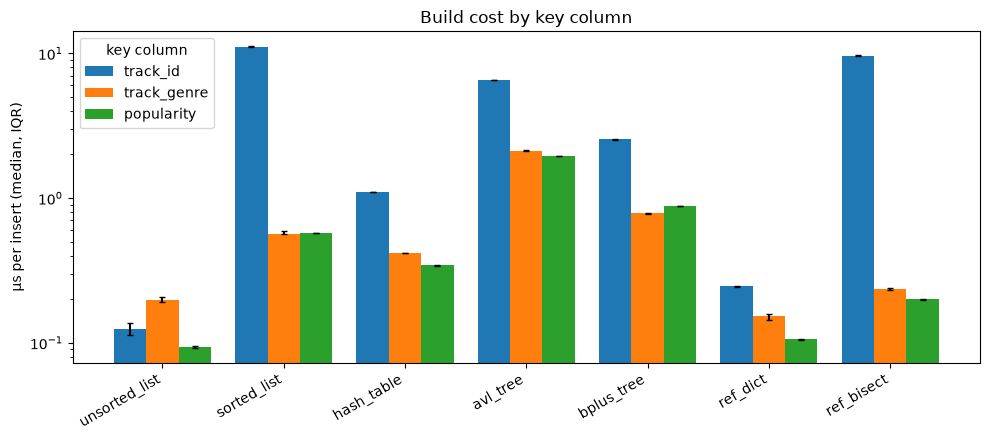

In [3]:
def grouped_bars(ax, operation, param=None, ylabel=""):
    width = 0.8 / len(COLUMNS)
    x = np.arange(len(INDEXES))
    for i, col in enumerate(COLUMNS):
        s = stats[(stats["key_column"] == col) & (stats["operation"] == operation)]
        if param is not None:
            s = s[s["operation_param"] == param]
        s = s.set_index("index_type").loc[INDEXES]
        err = [s["median"] - s["q25"], s["q75"] - s["median"]]
        ax.bar(x + i * width, s["median"], width, yerr=err, label=col, capsize=2)
    ax.set_xticks(x + width)
    ax.set_xticklabels(INDEXES, rotation=30, ha="right")
    ax.set_yscale("log")
    ax.set_ylabel(ylabel)

fig, ax = plt.subplots(figsize=(10, 4.5))
grouped_bars(ax, "build", ylabel="µs per insert (median, IQR)")
ax.set_title("Build cost by key column")
ax.legend(title="key column")
plt.tight_layout()

## Point-lookup (hit) cost per lookup, by column

Each lookup returns *every* row id stored under the key, so with 1,000+ rows per key the result list is long.

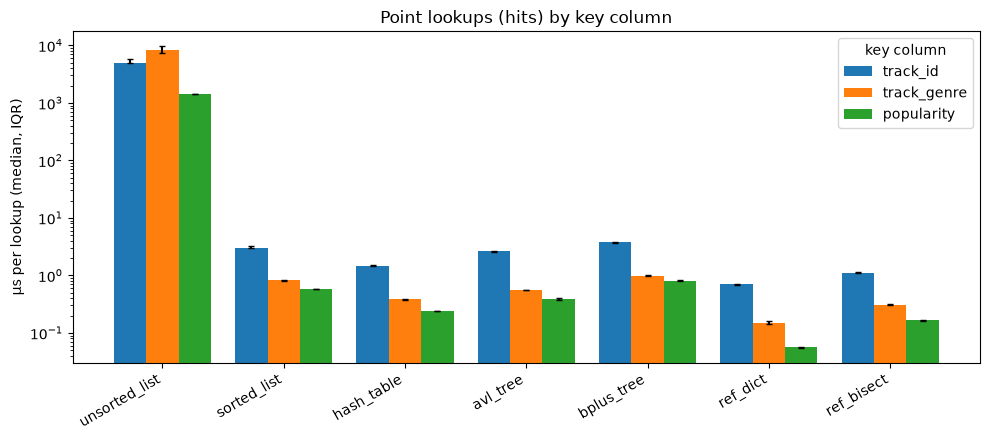

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5))
grouped_bars(ax, "point_hit", param=1.0, ylabel="µs per lookup (median, IQR)")
ax.set_title("Point lookups (hits) by key column")
ax.legend(title="key column")
plt.tight_layout()

## Range queries on `popularity`

Selectivity is the fraction of the 101 distinct popularity values a range covers, so 0.01 is one value (about 1,129 rows),
0.1 is ten values and 0.25 is twenty-five values (about 28,000 rows).

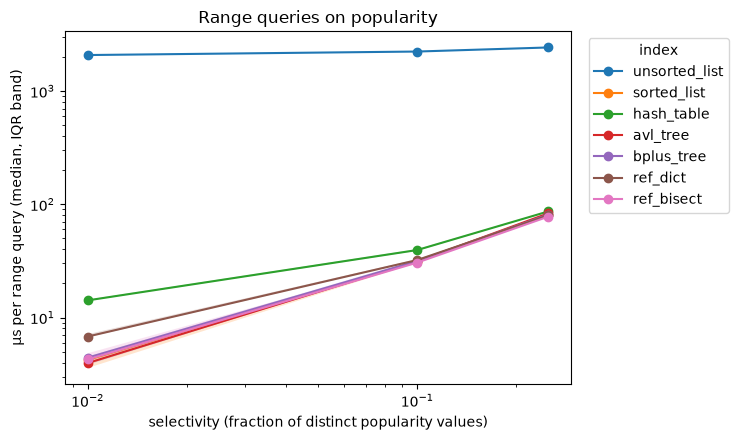

In [5]:
rng_stats = stats[(stats["key_column"] == "popularity") & (stats["operation"] == "range")].copy()
rng_stats["selectivity"] = rng_stats["operation_param"].astype(float)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for index_type in INDEXES:
    s = rng_stats[rng_stats["index_type"] == index_type].sort_values("selectivity")
    ax.plot(s["selectivity"], s["median"], marker="o", label=index_type)
    ax.fill_between(s["selectivity"], s["q25"], s["q75"], alpha=0.2)
ax.set(xscale="log", yscale="log", xlabel="selectivity (fraction of distinct popularity values)",
       ylabel="µs per range query (median, IQR band)", title="Range queries on popularity")
ax.legend(title="index", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

## Counters and structure

Counters are deterministic. Height, rotations and splits are measured after the build (the build row).

In [6]:
build = e7[e7["operation"] == "build"]
tree = (build[build["index_type"].isin(["avl_tree", "bplus_tree"])]
        .groupby(["index_type", "key_column"])[["height", "rotations", "splits"]].median().reindex(COLUMNS, level=1))
tree

height  rotations  splits
index_type key_column                            
avl_tree   track_id       20.0    62826.0     0.0
           track_genre     7.0      105.0     0.0
           popularity      8.0       91.0     0.0
bplus_tree track_id        4.0        0.0  4330.0
           track_genre     2.0        0.0     6.0
           popularity      2.0        0.0     4.0

In [7]:
hits = e7[e7["operation"] == "point_hit"]
(hits[hits["comparisons"].notna()]
 .groupby(["index_type", "key_column"])[["comparisons_per_op", "nodes_visited_per_op"]].median()
 .round(2).reindex(COLUMNS, level=1))

comparisons_per_op  nodes_visited_per_op
index_type    key_column                                           
avl_tree      track_id                  15.73                 15.73
              track_genre                5.92                  5.92
              popularity                 5.75                  5.75
bplus_tree    track_id                  16.76                  4.00
              track_genre                6.97                  2.00
              popularity                 7.17                  2.00
hash_table    track_id                   1.34                  1.00
              track_genre                1.31                  1.00
              popularity                 1.00                  1.00
sorted_list   track_id                  17.52                  0.00
              track_genre                7.89                  0.00
              popularity                 7.79                  0.00
unsorted_list track_id              114000.00                  0.00
              track_genre           114000.00                  0.00
              popularity            114000.00                  0.00

## Observations
- Build cost: building gets cheaper when many rows share a key. If the key is already in the index, the row is just added to that key's list, so the sorted list doesn't shift anything and the AVL tree doesn't rotate. For example, going from track_id to popularity, the sorted list drops from 11.1 to 0.6 µs per insert, and the AVL tree's rotations drop from 62,826 to 91. The trees are also shorter (AVL height 20 → 8, B+ height 4 → 2) because there are only about 100 different popularity values. The unsorted list stays fast either way because it just adds each row to the end.
- Point lookups: with fewer different keys, lookups in the sorted list, trees and hash table are faster because they have less to search. For example, AVL takes 0.38 µs on popularity vs 2.6 µs on track_id. The unsorted list is different: it checks all 114,000 rows every time in every column, but its time still varies (1,439, 5,035 and 8,398 µs). I'm not sure why, and it's probably down to the kind of keys being compared.
- Range queries on popularity: at a large range (25% of values) all the ordered indexes and the references cost about the same (about 80 µs), because most of the time goes to copying the many rows returned. At a small range (1%) the trees and sorted list take about 4 µs and the hash table about 14 µs, since the hash table has to look at every key. That's cheap here because there are only 101 keys. The unsorted list takes over 2,000 µs because it scans every row.